In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "config" / "params.yaml").exists(): ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from gfr import config; cfg = config.load()

# 01 - Cleaning & exploring the Gorkha 2015 damage survey
260,601 buildings (DrivenData *Richter's Predictor* subset of the Nepal 2015 Open Data Portal survey). Damage grade: 1 = low, 2 = medium, 3 = near-complete destruction.

In [2]:
from gfr import data_prep as D
df = D.load_clean(save=False)
df.shape

(260601, 48)

In [3]:
df[['damage_grade','floors','age','age_c','bclass']].describe(include='all')

,damage_grade,floors,age,age_c,bclass
count,260601.000000,260601.000000,259211.000000,259211.000000,260601
unique,NaN,NaN,NaN,NaN,8
top,NaN,NaN,NaN,NaN,MM_STONE
freq,NaN,NaN,NaN,NaN,200889
mean,2.238272,2.129554,21.341706,21.236117,NaN
std,0.611814,0.726629,19.606818,19.001746,NaN
min,1.000000,1.000000,0.000000,0.000000,NaN
25%,2.000000,2.000000,10.000000,10.000000,NaN
50%,2.000000,2.000000,15.000000,15.000000,NaN
75%,3.000000,2.000000,30.000000,30.000000,NaN


### Data-quality notes
- `age == 995` is a survey code (unknown / very old) -> set to NaN and flagged (`age_unknown`).
- Ages are capped at 100 y for modelling; floors capped at 6.
- Pure RC frames are separated from RC + masonry hybrids: the hybrids are damaged far more often.

In [4]:
D.summary(df).round(3)

,n,dg1,dg2,dg3,mean_floors,median_age
bclass,,,,,,
MM_STONE,200889,0.042,0.568,0.389,2.124,20.0
MM_BRICK,15403,0.029,0.640,0.330,2.791,35.0
CM_STONE,3273,0.118,0.716,0.166,2.023,15.0
CM_BRICK,15514,0.335,0.603,0.062,1.816,10.0
RC_NE,4454,0.527,0.442,0.031,2.147,5.0
RC_E,2665,0.687,0.295,0.018,2.402,5.0
RC_MIX,8018,0.284,0.555,0.162,2.198,10.0
TIM_OTH,10385,0.395,0.514,0.092,1.631,10.0


In [5]:
mas = [f'has_superstructure_{m}' for m in D.MASONRY_FLAGS]
rc = df[df.has_superstructure_rc_non_engineered.eq(1) | df.has_superstructure_rc_engineered.eq(1)].copy()
rc['with_masonry_flag'] = rc[mas].sum(axis=1) > 0
rc.groupby('with_masonry_flag').damage_grade.value_counts(normalize=True).unstack().round(3)

damage_grade,1,2,3
with_masonry_flag,,,
False,0.587,0.387,0.026
True,0.284,0.555,0.162


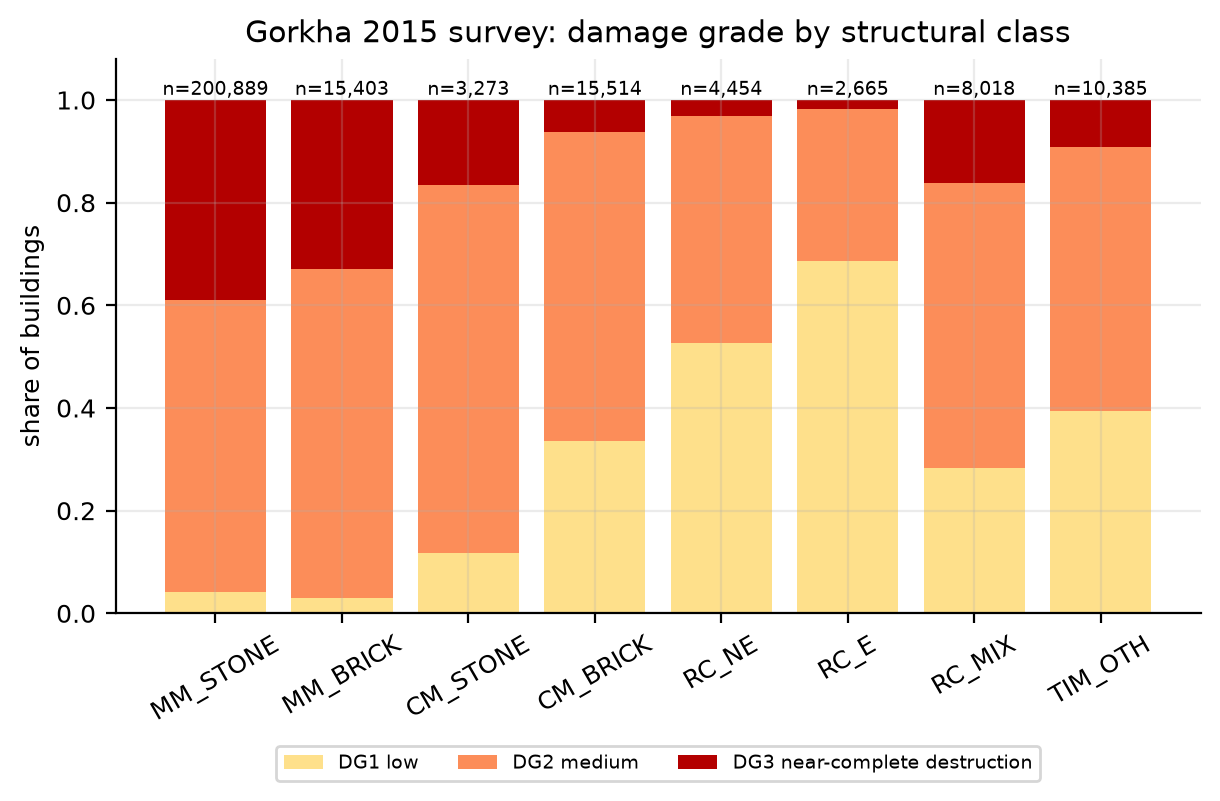

In [6]:
display(Image('results/figures/01_damage_by_class.png'))

In [7]:
df.groupby('geo_level_1_id').damage_grade.agg(['size','mean']).round(2).T

geo_level_1_id,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
size,4011.00,2701.00,931.00,7540.00,14568.00,2690.00,24381.00,18994.0,19080.00,3958.00,22079.00,8220.00,3194.00,9608.00,1714.00,...,4332.00,21813.00,3189.00,372.00,17216.00,14889.00,6252.0,1121.00,1310.00,5624.00,22615.00,12532.00,265.00,396.00,2686.00
mean,2.07,1.96,2.16,2.33,2.16,1.92,2.16,2.3,2.49,2.03,2.34,2.34,2.15,1.94,2.05,...,2.17,2.79,2.71,2.06,1.93,2.56,2.0,2.19,1.89,2.05,1.73,2.45,2.41,2.08,2.02


`geo_level_1_id` (31 regions) is anonymised in this subset; its mean damage grade is a proxy for local shaking - the basis of the latent-intensity fragility model in notebook 02.